In [44]:
import gc
import multiprocessing as mp
import os
import pickle
import time
import numpy as np
import pandas as pd
import scipy.interpolate
import scipy.integrate
import skopt
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm, trange

In [2]:
n_cpus = len(os.sched_getaffinity(0))

In [3]:
sns.set_style('white')

In [ ]:
def intervals_overlap(intervals):
    '''
    Return symmetric square matrix indicating which intervals in a sequence overlap.

    Arg
    - itervals: iterable of (start, end), len=d
        Assumes end >= start
        Start and end are inclusive.
        Can be a np.ndarray where rows are pairs, i.e., shape is (d, 2)

    Returns: np.ndarray, shape=(d, d), dtype=bool
      Element r, c is True if interval r overlaps with interval c.
      Diagonal is 0.
    '''
    assert all((end >= start for start, end in intervals))
    d = len(intervals)
    overlap = np.zeros((d, d), dtype=bool)
    for i, j in itertools.combinations(range(d), 2):
        start1, end1 = intervals[i]
        start2, end2 = intervals[j]
        overlap[i, j] = (start1 >= start2 and start1 <= end2) or (end1 >= start2 and end1 <=end2)
    return overlap | overlap.T

In [82]:
pos_intron_nanog

array([[  28,  120,  445, 4315, 5227],
       [ 323,  323, 4049, 5140, 5653]])

In [52]:
def simulate_transcripts(
    alpha, beta, gamma, v,
    pos_intron, gene_length, n_time_steps, t_wash=600,
    rng=None, log10=False, alt_splicing=True):
    '''
    Args
    - Parameters
      - alpha: float
          Production rate (transcripts / time)
      - beta: float
          Decay rate (1 / time), must be between 0 and 1
      - gamma: float
          Splicing rate (1 / time), must be between 0 and 1.
          Assumed to be constant for different splice junctions in the same gene
      - v: float
          Elongation velocity (nucleotides / time)
    - Experiment parameters
      - pos_intron: np.ndarray. shape=(2, n_introns)
          Coordinates of introns, 1-indexed
      - gene_length: int
          Number of nucleotides from transcription start site to transcription end site
      - t_wash: int. default=600
          Time at which transcription initiation stops
      - n_time_steps: int
          Number of time steps
    - Simulation arguments
      - rng: np.random.Generator. default=None
          Random number generator. If None, uses np.random.default_rng().
      - log10: bool, default=False
          Whether parameters are given as log10-transformed values
      - alt_splicing: bool, or np.ndarray of shape (n_introns, n_introns). default=True
          True: check for overlapping introns; only allow physically possible splicing combinations
          False: do not check for overlapping introns; assume all introns are spliced independently
          np.ndarray: square, symmetric matrix denoting whether any pair of introns overlap - see intervals_overlap()
    '''
    if log10:
        alpha = 10**alpha
        beta = 10**beta
        gamma = 10**gamma
        v = 10**v
    
    if alt_splicing is True:
        alt_splicing = intervals_overlap(pos_intron.T)
    if isinstance(alt_splicing, np.ndarray):
        assert np.array_equal(alt_splicing, alt_splicing.T)
        if alt_splicing.sum() == 0:
            alt_splicing = False

    assert gamma >= 0 and gamma < 1
    assert beta >= 0 and beta < 1
    assert v >= 0 and alpha >=0
    if rng is None:
        rng = np.random.default_rng()
    n_introns = pos_intron.shape[1]

    # --- initial condition: elongating transcripts at the time of labeling initiation ---

    # transcripts: np.ndarray
    # - rows: each row represents a transcript
    # - columns: number of columns = n_introns + 1
    #   - column i: denote whether intron i has been spliced (1) or not (0)
    #   - column -1: position of the transcript
    n_transcripts = rng.poisson(gene_length * alpha / v)
    transcripts = np.zeros((n_transcripts, n_introns + 1), dtype=int)
    transcripts[:, -1] = rng.choice(gene_length, n_transcripts)

    # splice initial transcripts
    if alt_splicing is False:
        mask_contains_intron = transcripts[:, [-1]] > pos_intron[1, :]
        log_prob_unspliced = np.log(1 - gamma) * ((transcripts[:, [-1]] - pos_intron[1, :]) / v)
        transcripts[:, :-1] = mask_contains_intron & (np.log(rng.random(transcripts[:, :-1].shape)) > log_prob_unspliced)
    else:
        for j in rng.permutation(n_introns):
            if transcript['spliced'][j] == 0 and transcript['position'] >= transcript_info[j][1] and rng.random() < gamma:
              transcript['spliced'][j] = 1

    # initialize counts of unspliced and spliced introns
    counts = np.zeros((n_time_steps, n_introns, 2)) # time, intron, unspliced and spliced count
    counts[0, :, 0] = np.sum(transcripts[:, :-1] == 0, axis=0)
    counts[0, :, 1] = np.sum(transcripts[:, :-1], axis=0)

    # --- simulation over time ---
    for t in range(1, n_time_steps):
        # decay
        mask_decay = (transcripts[:, -1] == gene_length) & (rng.random(n_transcripts) < beta)
        transcripts = transcripts[~mask_decay, :]
        # transcripts = np.delete(transcripts, mask_decay, axis=0)
        n_transcripts = transcripts.shape[0]

        # splice
        mask_contains_intron = (transcripts[:, [-1]] > pos_intron[1, :]) & (transcripts[:, :-1] == 0)
        transcripts[:, :-1] |= mask_contains_intron & (rng.random(transcripts[:, :-1].shape) < gamma)

        # elongate
        transcripts[:, -1] = np.minimum(transcripts[:, -1] + int(np.rint(v)), gene_length)

        # initiation
        if t < t_wash:
            n_new_transcripts = rng.poisson(alpha)
            if n_new_transcripts > 0:
                new_transcripts = np.zeros((n_new_transcripts, n_introns + 1), dtype=int)
                new_transcripts[:, -1] = rng.choice(np.minimum(int(np.rint(v)), gene_length), n_new_transcripts)
                transcripts = np.append(transcripts, new_transcripts, axis=0)
                n_transcripts = transcripts.shape[0]

        # count spliced and unspliced transcripts
        counts[t, :, 0] = np.sum(transcripts[:, :-1] == 0, axis=0)
        counts[t, :, 1] = np.sum(transcripts[:, :-1], axis=0)

    return counts

In [5]:
def average_simulations(n, *args, seed=None, use_tqdm=True, use_pool=True, **kwargs):
    if use_pool:
        if use_tqdm:
            pbar = tqdm(total=n)
            def update(*a):
                pbar.update()
        results = []
        with mp.Pool(n_cpus) as p:
            for i in range(n):
                kwargs['rng'] = np.random.default_rng(seed + i) if isinstance(seed, int) else None
                results.append(p.apply_async(
                    simulate_transcripts,
                    args,
                    kwargs.copy(),
                    callback=update if use_tqdm else None))
            p.close()
            p.join()
        counts_all = [result.get() for result in results]
        # success = [result.successful() for result in results]
        # if not all(success):
        #     print(f'{sum(success)} / {len(success)} simulations succeeded.')
        # counts_all = [result.get() for i, result in enumerate(results) if success[i]]
        # if sum(success) == 0:
        #     counts_all = []
        #     range_fun = trange if use_tqdm else range
        #     for i in range_fun(n):
        #         kwargs.update(dict(rng=np.random.default_rng(seed + i) if isinstance(seed, int) else None))
        #         counts = simulate_transcripts(*args, **kwargs)
        #         counts_all.append(counts)
    else:
        counts_all = []
        range_fun = trange if use_tqdm else range
        for i in range_fun(n):
            counts = simulate_transcripts(
                *args, **kwargs,
                rng=np.random.default_rng(seed + i) if isinstance(seed, int) else None)
            counts_all.append(counts)
    return np.mean(np.stack(counts_all), axis=0), np.var(np.stack(counts_all), axis=0)

# Read data

In [67]:
# Experimental setup
time_points_min = [0, 10, 15, 20, 25, 30, 45, 60, 75, 90, 120, 240]
t_wash = 600
data_time = np.array(time_points_min) * 60 + t_wash - 1

In [68]:
!wget -nc -q https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_mouse/release_M25/gencode.vM25.annotation.gtf.gz

In [69]:
file_exons = 'exons.counts'
file_introns = 'introns.counts'
file_junctions = 'junctions.counts'
file_annot = 'gencode.vM25.annotation.gtf.gz'
file_norm = 'normalized_counts_filtered.csv'
columns_counts = ['gene', 'intron_position'] + [str(x) for x in time_points_min]
columns_gtf = ['chr', 'source', 'feature type', 'start', 'end', 'score', 'strand', 'phase', 'additional']

In [70]:
df_junctions = pd.read_csv(file_junctions, sep='\t', header=None, names=columns_counts)
df_introns = pd.read_csv(file_introns, sep='\t', header=None, names=columns_counts)
df_norm = pd.read_csv(file_norm)
df_annot = pd.read_csv(file_annot, sep='\t', comment='#', names=columns_gtf)

In [71]:
# Nanog
gene_length_nanog = int(df_norm.loc[df_norm['gene name'] == 'Nanog', 'gene length'])

transcript_annot_nanog = df_annot.loc[df_annot['additional'].str.contains('gene_name "Nanog"') & (df_annot['feature type'] == 'transcript')] \
  .copy() \
  .pipe(lambda x: x.assign(length=abs(x['start'] - x['end']) + 1)) \
  .pipe(lambda x: x.loc[x['length'] == gene_length_nanog]) \
  .squeeze()

In [72]:
pos_intron_nanog = (np.array(
  df_junctions.loc[df_junctions['gene'] == 'Nanog', 'intron_position'] \
    .map(lambda s: s.split(':')[1]) \
    .map(lambda s: [int(x) for x in s.split('-')]) \
    .to_list()
) - transcript_annot_nanog['start'] + 1).T

In [73]:
data_counts_nanog = np.stack(
    (df_introns.loc[df_introns['gene'] == 'Nanog', [str(x) for x in time_points_min]].values.T,
     df_junctions.loc[df_junctions['gene'] == 'Nanog', [str(x) for x in time_points_min]].values.T),
    axis=2)

In [74]:
del df_annot
gc.collect()

66

# Fitting

In [75]:
def loss(x, data_time, data_counts, pos_intron, gene_length, n=20, kwargs=None):
    if kwargs is None:
        kwargs = dict()
    alpha, beta, gamma, v = x
    t = np.arange(data_time[-1] + 1)
    sim_counts, _ = average_simulations(
        n,
        alpha, beta, gamma, v,
        pos_intron, gene_length, t,
        **kwargs)
    return np.sum((data_counts - sim_counts[data_time, :, :])**2)

In [76]:
x0 = (1e-1, 1e-3, 1e-2, 50)
bounds = [(1e-4, 1), (1e-5, 1e-1), (1e-4, 0.5), (1, 200)]

In [ ]:
with open('current_res.pkl', 'rb') as f:
    res = pickle.load(f)

In [77]:
def loss_nanog(x):
    return loss(x, data_time, data_counts_nanog, pos_intron_nanog, gene_length_nanog, n=25, kwargs=dict(log10=True, use_tqdm=False))

def callback(res):
    print(res.x_iters[-1])
    print(res.func_vals[-1])
    with open('current_res.pkl', 'wb') as f:
        pickle.dump(res, f)
    print('-----')

res = skopt.gp_minimize(
    loss_nanog,
    [(np.log10(a), np.log10(b)) for a, b in bounds],
    # x0=res.x_iters,
    # y0=res.func_vals,
    n_calls=200,
    callback=callback,
    random_state=0)

[-1.6286215270999262, -1.6229370056759298, -0.8264848950618822, 1.9495516648207372]
6785298.1856
-----
[-1.5057452128561102, -3.4624731708292003, -2.8994284151400773, 0.1304982619508478]
5849304.232000001
-----
[-2.909374821679547, -3.0893395307146, -0.9958122337997342, 1.1044418708689885]
6785822.2928
-----
[-2.4288608155966807, -1.655684945850489, -2.7519817230383805, 1.4914629199354812]
6786311.660800001
-----
[-2.5270338406378077, -1.1713793641878136, -3.4808466731684744, 2.0020968803277985]
6787066.2
-----
[-2.1055678189051577, -1.7963569920814222, -2.0747694152076797, 1.562122162245997]
6784795.779200001
-----
[-1.1174693810963325, -2.671920831699571, -2.012272543134932, 1.7455973067451025]
6768206.451199999
-----
[-3.5763695712488315, -3.10559832261337, -3.310762251196674, 1.6956708299237557]
6787075.968
-----
[-3.1337985823025125, -4.459127306378192, -2.801012134997653, 0.34440635898667754]
6754340.625600001
-----
[-3.110714446993649, -3.454044075496552, -0.6613153130573135, 1.

In [ ]:
def iterative_minimize(fun, bounds, x0, args=None, kwargs=None, n_calls=None, callback=None, random_state=None):
    if args is None:
        args = ()
    if kwargs is None:
        kwargs = {}
    n_params = len(x0)
    for i in n_params:
        
        x_cur = x0.copy()
        x_cur[i] = 
        fun(x0, *args, **kwargs)

In [ ]:
%debug

In [66]:
pos_intron_nanog

array([[  28,  120,  445, 4315, 5227],
       [ 323,  323, 4049, 5140, 5653]])

In [78]:
best_x = res.x # [-0.44816446255188525, -4.0, -3.294148122485756, 0.8378778008817098]
t = np.arange(data_time[-1] + 1)
counts_mean, counts_var = average_simulations(25, *best_x, pos_intron_nanog, gene_length_nanog, t, log10=True)

  0%|          | 0/25 [00:00<?, ?it/s]

In [81]:
10**np.array(res.x)

array([3.75045711e-02, 1.01463191e-04, 1.00000000e-04, 1.11820069e+00])

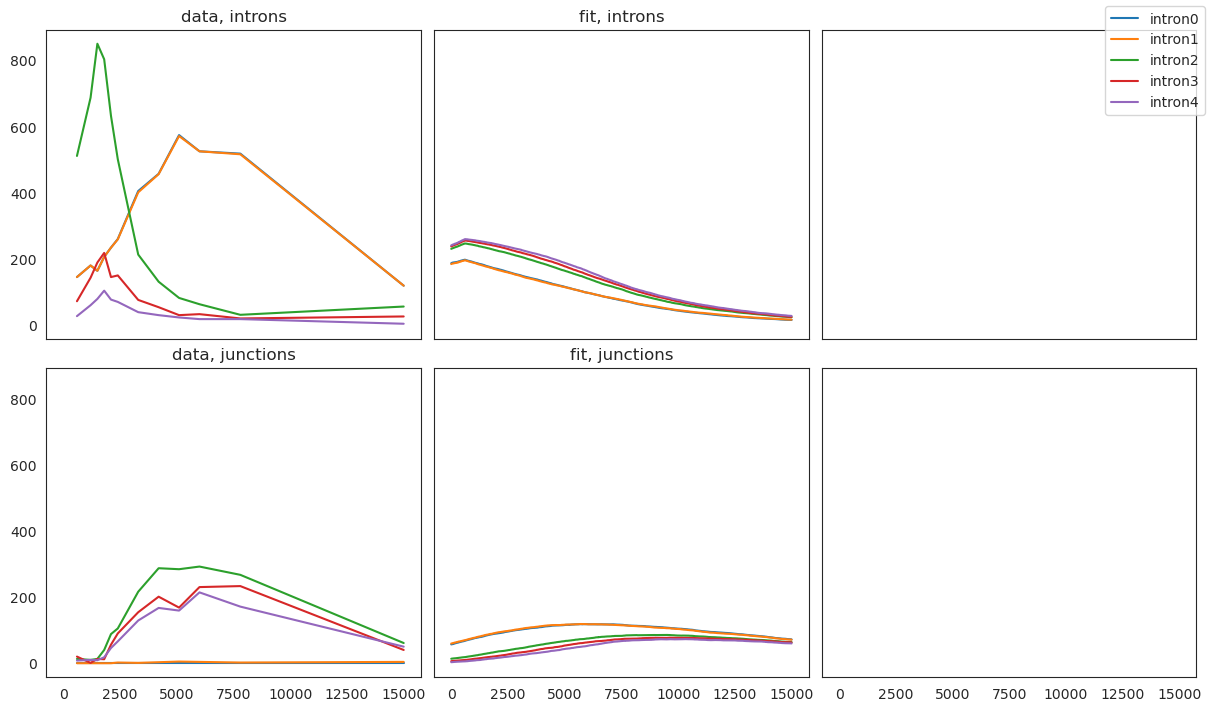

In [79]:
fig, axs = plt.subplots(2, 3, sharex=True, sharey=True, figsize=(12, 7), constrained_layout=True)
for j in range(data_counts_nanog.shape[1]):
    axs[0, 0].plot(data_time, data_counts_nanog[:, j, 0], label=f'intron{j}')
    axs[1, 0].plot(data_time, data_counts_nanog[:, j, 1], label=f'spliced{j}')
    
    axs[0, 1].plot(t, counts_mean[:, j, 0], label=f'intron{j}')
    axs[1, 1].plot(t, counts_mean[:, j, 1], label=f'spliced{j}')

axs[0, 0].set(title='data, introns')
axs[1, 0].set(title='data, junctions')
axs[0, 1].set(title='fit, introns')
axs[1, 1].set(title='fit, junctions')
fig.legend(*(axs[0,0].get_legend_handles_labels()))
# axs[0].legend()

# axs[1].plot(t, counts_mean[:, :, 0], label='introns')
# axs[1].plot(t, counts_mean[:, :, 1], label='exons')
# axs[1].legend()

# axs[2].plot(data_time, data_counts_nanog[:, :, 0], 'x', label='introns')
# axs[2].plot(data_time, data_counts_nanog[:, :, 1], 'x', label='spliced')
# axs[2].plot(t, counts_mean[:, :, 0], label='introns')
# axs[2].plot(t, counts_mean[:, :, 1], label='exons')
# axs[2].legend()